# AIT Dataset — Unsupervised Anomaly Detection

Dataset : https://zenodo.org/records/19483937#1

## Overview

The AIT Log Data Set is a collection of eight independent, realistic, miniature companies, each with its own network and its own story of a cyber-attack.


Each testbed simulates a small company network with common infrastructure:
- Mail servers (e.g., jonesmorgan_mail)
- File shares (internal_share, cloud_share)
- A WordPress webserver (intranet_server)
- Network infrastructure like a VPN (vpn) and firewall (inet-firewall)
- User workstations for simulated employees


The simulation runs for 4 to 6 days, generating a massive amount of "normal" background noise from simulated user activity. At some point, an attacker enters the network and executes a sequence of attack steps.


Each testbed contains those directories :

|Directory / File	|What It Contains	|Your Takeaway|
|----|----|---|
|`gather/`	|The raw logs from every host on the network. This includes everything: auth.log, syslog, apache, audit, suricata, dnsmasq, etc.	| Input data. It's noisy, voluminous, and untrustworthy on its own.|
|`labels/`	|The ground truth. This directory mirrors the gather/ structure. For every log file that contains attack events, there's a corresponding label file.	|The **evaluation** target. It tells exactly which lines are part of the attack.|
|`attacker_0/logs/attacks.log`	|A high-level, step-by-step narrative of the attack (e.g., 11:59 vpn_connect, 12:38 crack_wphash).	|The story guide. It gives the timeline and context for the ground truth.|
|`dataset.yml`	|Metadata specifying the exact simulation start/end times.	|Filter. Anything outside this window is setup/teardown noise and should be ignored.|

The security problem relies mainly on the fact its impossible to label an attack se don't even know exist.

Instead : we  train an autoencoder on benign traffic only, use reconstruction error as the anomaly score, pick a threshold from benign validation data, then evaluate on a labeled mixed test set.

Dataset choice

 evaluated eight candidates. The key criteria were:

Does it contain raw logs (not pre-computed features)?

Does it have benign background traffic? (needed to train semi-supervised)

Does it have labeled attacks? (needed to evaluate)

Does it have a permissive license?

Is it realistic? (not synthetic toy data)

Candidates considered and rejected:

Dataset	Rejection reason
Crowdsensing (2026)	308 GB, IoT domain not Linux servers
Linux-APT-Dataset-2024	Only ~243 attack steps, no benign background
DEDALE	~1 TB, too large for a course project
CAM-LDS	No benign traffic at all — can't train semi-supervised
UNSW-NB15, TON_IoT	Tabular flow features, not log sequences
Entente	Graph-structured, requires GNN, out of scope
Security-Gym	RL environment, not a classification benchmark
We chose AIT Log Data Set V2.1 as the primary dataset. Its properties:

8 testbeds (fox, harrison, russellmitchell, santos, shaw, wardbeck, wheeler, wilson)

Each is a simulated small enterprise network (mail, file share, WordPress, VPN, firewall, user workstations)

4–6 days of simulation with normal user behavior

At some point, an attack chain runs: scans → webshell upload → password cracking → privilege escalation → RCE → DNS exfiltration

Rich logs: auth.log, syslog, apache, audit, suricata, dnsmasq, openvpn, logstash

Ground truth: JSONL files that say "line N of file X is part of attack Y"

Natural federation silos: the 8 testbeds can be 8 clients in FL

We chose Mendeley IoT as a smoke-test dataset. It's tiny (~30 MB), tabular, purpose-built for FL, and lets us validate the pipeline in minutes before touching a 26 GB dataset.



## Testbed : the fox silo

We explore the **fox** silo first before touching the other 7. The goal of this notebook is just to understand the data — no models yet.


At the end of this notebook we should be able to answer:
1. What hosts exist, and which ones do we *exclude* from training?\n",
2. Which log files actually carry attack signal, and which ones are noise?\n",
3. How do labels map to raw log lines, and do they actually line up?\n",
4. Which attack types are common vs rare? (because the model will not learn the rare ones the same way),
5. What's a reasonable time-window size for aggregation?\n",


## 1. Setup & Imports:

### imports

In [6]:
import pickle
import random
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import yaml, json


In [7]:
FOX = Path("../datasets/ait/fox").resolve()
assert FOX.exists(), f"Download fox first: {FOX}"

GATHER = FOX / "gather"
LABELS = FOX / "labels"
pd.set_option("display.max_rows", 100)

## 2. Data Exploration

Next points :
1. Whats the simulation window ?
2. whats host mean ?
3. In which folder are there the most logs ?
4. What does a Raw log file look like ?
5. 






### Simulation Window

Global start and end-time for the simulation.

From the Zenodo description, fox runs 2022-01-15 → 2022-01-20. 

MUST filter out logs outside this window later — anything outside it is testbed setup noise.

In [8]:
with open(FOX / "dataset.yaml") as f:  # /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/ait/fox/dataset.yaml
    meta = yaml.safe_load(f)
print(json.dumps(meta, indent=2, default=str))

{
  "name": "processed_fox_scenario",
  "start": "2022-01-15T00:00:00",
  "end": "2022-01-20T00:00:00"
}


### 1. Host inventory

30 hosts : 
| Host  | Descritpion |
|------|------|
|mail servers|  `mail`, `jonesmorgan_mail`, `miller_mail`, ...|
|network infra| `vpn`, `inet-firewall`, `inet-dns`|
|file shares|`cloud_share`, `internal_share`|
|logstash / monitoring stack | `monitoring`|
|users | `internal_employee_0..4`, `remote_employee_0..3`, `ext_user_0..6`|
|attacker |`attacker_0`|

Note :
- `attacker_0`must be excluded from the training data, lest the model learns attack patterns as normal behaviour.
-`attacker_0/logs/attacks.log` has the exact attack-step timestamps. Useful for sanity-checking the model later — not directly useful for training.

In [9]:
hosts = sorted(p.name for p in GATHER.iterdir() if p.is_dir())
print(f"{len(hosts)} hosts:")
for h in hosts:
    print(f"  {h}")

30 hosts:
  attacker_0
  cloud_share
  ext_user_0
  ext_user_1
  ext_user_2
  ext_user_3
  ext_user_4
  ext_user_5
  ext_user_6
  inet-dns
  inet-firewall
  internal_employee_0
  internal_employee_1
  internal_employee_2
  internal_employee_3
  internal_employee_4
  internal_share
  intranet_server
  jonesmorgan_mail
  mail
  miller_mail
  monitoring
  remote_employee_0
  remote_employee_1
  remote_employee_2
  remote_employee_3
  taylorcruz_mail
  vpn
  webserver
  whittaker_mail


### 2. Log-file inventory

What files doe we have (size, shape, location).

Notewothy :
- `suricata` (2 GB) — network alert logs. Huge. Mostly redundant for our purposes (the firewall already logs the DNS exfil we care about) and slow to parse. **Skip unless you specifically need a network-level detector.**
- `intranet-server` (1.1 GB) — logstash output from the intranet server. WordPress request traffic lives here.
- `internal-share` (1.1 GB) — logstash from the file-share host. Probably not useful for the attacks in this silo.
- `logs` (126 MB) — generic log folder. **Contains the attacker_0 attack timeline AND the inet-firewall dnsmasq logs.** The dnsmasq logs are where 44k of our labeled lines live. **Critical**.
- `audit` (4.7 MB) — auditd logs. Tiny but dense. User + privilege activity lives here. **Also critical.**
- `apache2`, `redis` — 0 MB. Empty. The WordPress activity is shipped via logstash, so it appears under `intranet-server`, not `apache2`. Ignore these two.


In [28]:
# Line inventory — count lines AND bytes per log file

rows = []
for host_dir in GATHER.iterdir():
    logs_dir = host_dir / "logs"
    if not logs_dir.is_dir():
        continue
    for log_file in logs_dir.rglob("*.log"):
        # Count lines without loading into memory
        with open(log_file, "rb") as f:
            n_lines = sum(1 for _ in f)
        rows.append({
            "host":     host_dir.name,
            "log_type": log_file.parent.name,
            "file":     log_file.name,
            "lines":    n_lines,
            "mb":       round(log_file.stat().st_size / 1e6, 2),
        })

inv = pd.DataFrame(rows)

# Aggregate per log type
per_type = (inv.groupby("log_type")[["file", "lines", "mb"]]
            .agg({"file": "count", "lines": "sum", "mb": "sum"})
            .sort_values("lines", ascending=False))
per_type["avg_bytes_per_line"] = (per_type["mb"] * 1e6 / per_type["lines"]).round(0)
print(per_type.to_string())

                             file     lines       mb  avg_bytes_per_line
log_type                                                                
suricata                       27  25002245  2018.45                81.0
intranet-server                92   1358903  1140.92               840.0
internal-share                 92   1339750  1118.88               835.0
logs                           45    757148   126.30               167.0
logstash                       17    385760    82.92               215.0
horde                          10     93935    28.30               301.0
audit                           7     24082     4.76               198.0
ait.aecid.attacker.wpdiscuz     1       957   128.05            133804.0
apache2                         8         0     0.00                 NaN
redis                           1         0     0.00                 NaN


### 2.1 - Raw log file

What does the raw logs look like ? No guarantees format is the same between silos, so we'll have to check it each time.

The format for the `fox` silo is :
```bash
type=<TYPE> msg=audit(<epoch>.<ms>:<serial>): <key=value pairs>
```

- type : event type (USER_ACCT, USER_START, CRED_ACQ ...)
- msg : ? contains the epoch timestamp
- key :



In [11]:
# Pick the largest audit log on the intranet server — rich and well-documented
example = GATHER / "intranet_server" / "logs" / "audit" / "audit.log"
if not example.exists():
    example = next(GATHER.rglob("audit.log"))

with open(example) as f:
    for i, line in enumerate(f, start=1):
        if i > 5:
            break
        print(f"{i:>5}  {line.rstrip()[:180]}")

    1  type=USER_ACCT msg=audit(1642205342.071:371): pid=9852 uid=0 auid=4294967295 ses=4294967295 msg='op=PAM:accounting acct="root" exe="/usr/sbin/cron" hostname=? addr=? terminal=cron 
    2  type=CRED_ACQ msg=audit(1642205342.071:372): pid=9852 uid=0 auid=4294967295 ses=4294967295 msg='op=PAM:setcred acct="root" exe="/usr/sbin/cron" hostname=? addr=? terminal=cron res=
    3  type=LOGIN msg=audit(1642205342.071:373): pid=9852 uid=0 old-auid=4294967295 auid=0 tty=(none) old-ses=4294967295 ses=65 res=1
    4  type=USER_START msg=audit(1642205342.075:374): pid=9852 uid=0 auid=0 ses=65 msg='op=PAM:session_open acct="root" exe="/usr/sbin/cron" hostname=? addr=? terminal=cron res=success'
    5  type=CRED_DISP msg=audit(1642205342.079:375): pid=9852 uid=0 auid=0 ses=65 msg='op=PAM:setcred acct="root" exe="/usr/sbin/cron" hostname=? addr=? terminal=cron res=success'


### 3. labels peek

Labels are `.jsonl` files.

```json
{"line": 2079, "labels": ["attacker_change_user", "escalate"], ...}
```
- `line`: which raw-line number it points to (1-indexed)
- `labels`: which attack steps this line belongs to (a line can have several — e.g. the same sudo command counts as both `escalate` and `attacker_change_user`)
- `rules`: which rule fired to assign the label (for debugging only, ignore)

The previous line then literally means: *line 2079 of `gather/intranet_server/logs/audit/audit.log` is part of the privilege-escalation attack.*

To build the normal/bening training set, we'll have to remove all the lines listed in `label`.



In [12]:
label_file = LABELS / example.relative_to(GATHER).with_suffix(".log")
# (labels dir mirrors gather dir structure exactly)

with open(label_file) as f:
    for i, line in enumerate(f, start=1):
        if i > 3:
            break
        print(f"{line.rstrip()}")

{"line": 2079, "labels": ["attacker_change_user", "escalate"], "rules": {"attacker_change_user": ["attacker.escalate.audit.su.login", "attacker.escalate.audit.systemd.session"], "escalate": ["attacker.escalate.audit.su.login", "attacker.escalate.audit.systemd.session"]}}
{"line": 2080, "labels": ["attacker_change_user", "escalate"], "rules": {"attacker_change_user": ["attacker.escalate.audit.su.login"], "escalate": ["attacker.escalate.audit.su.login"]}}
{"line": 2081, "labels": ["attacker_change_user", "escalate"], "rules": {"attacker_change_user": ["attacker.escalate.audit.su.login"], "escalate": ["attacker.escalate.audit.su.login"]}}


### 4. label categories

Notes :
- For DNSteal, the same DNS query line is labeled as dnsteal, attacker, and dnsteal-received.
- Top three labels are identical, they are the same events. and represent >99% of the data.
- The rest of the attacks (scans, privilege escalation, webshell) are less than <`1%`. 


If we keep the data as is, the model will pretty much only detect `dns attacks`.
-> downsampling ? data augmentation ?

In [26]:
all_labels = {}
for lf in LABELS.rglob("*.log"):
    with open(lf) as f:
        for raw in f:
            raw = raw.strip()
            if not raw:
                continue
            rec = json.loads(raw)
            for lbl in rec["labels"]:
                all_labels[lbl] = all_labels.get(lbl, 0) + 1

label_df = pd.DataFrame(
    sorted(all_labels.items(), key=lambda kv: -kv[1]),
    columns=["label", "count"],
)
print(label_df.to_string(index=False))

# Count unique labeled lines, not (line × label) pairs
unique_labeled_lines = 0
for lf in LABELS.rglob("*.log"):
    seen_here = set()
    for raw in open(lf):
        if raw.strip():
            seen_here.add(json.loads(raw)["line"])
    unique_labeled_lines += len(seen_here)

print("\n")
print(f"Unique labeled lines: {unique_labeled_lines:,}")
print("---> dnsteal, attacker and dnsteal-received represent the SAME attack.")


                 label  count
               dnsteal  44018
              attacker  44018
      dnsteal-received  44016
              foothold    606
              dns_scan    414
          service_scan     90
              escalate     83
          network_scan     62
       crack_passwords     46
          attacker_vpn     28
     escalated_command     18
escalated_sudo_command     18
  attacker_change_user     14
                wpscan      8
escalated_sudo_session      6
          webshell_cmd      6
            traceroute      4
  exfiltration-service      2


Unique labeled lines: 44,707
---> dnsteal, attacker and dnsteal-received represent the SAME attack.


In [ ]:
#  Label counts per log file
rows = []
for lf in LABELS.rglob("*.log"):
    raw_path = GATHER / lf.relative_to(LABELS)
    if not raw_path.exists():
        continue
    n_lines = sum(1 for _ in open(lf) if _.strip())
    rows.append({
        "log_file": str(lf.relative_to(LABELS)),
        "labeled":  n_lines,
        "raw_lines": sum(1 for _ in open(raw_path)),
    })
pd.DataFrame(rows).sort_values("labeled", ascending=False)

,log_file,labeled,raw_lines
4,inet-firewall/logs/dnsmasq.log,44600,240582
0,monitoring/logs/logstash/intranet-server/2022-...,46,1920
1,vpn/logs/openvpn.log,28,7299
3,intranet_server/logs/audit/audit.log,19,2887
2,intranet_server/logs/auth.log,12,572
5,internal_share/logs/audit/audit.log,2,898


Note :
- `dnsmasq.log` is where 99% of labeled lines live.
- 18.5% from it (44600/240582) is labeled. Which leaves a lot of benign traffic for our models to learn from.


### 4.1 - label Alignment check

In [16]:
def verify_alignment(sample_n=3):
    """For a few random labeled files, confirm that the labeled line
    numbers point to real lines in the raw log — and that the labeled
    lines look like the attack they claim to be."""
    label_files = sorted(LABELS.rglob("*.log"))
    # Sample across different log types
    seen = set()
    samples = []
    for lf in label_files:
        lt = lf.parent.name
        if lt in seen:
            continue
        n = sum(1 for line in open(lf) if line.strip())
        if n:
            samples.append(lf)
            seen.add(lt)
        if len(samples) >= sample_n:
            break

    for lf in samples:
        raw_path = GATHER / lf.relative_to(LABELS)
        with open(raw_path) as f:
            raw_lines = f.readlines()

        first_rec = json.loads(next(open(lf)))
        ln = first_rec["line"]
        # line 1 in the file is `raw_lines[0]` because label line numbers are 1-indexed
        ok = 1 <= ln <= len(raw_lines)
        print(f"\n{lf.relative_to(LABELS)}")
        print(f"  labels: {first_rec['labels']}")
        print(f"  points to line {ln} of {len(raw_lines):,} in raw log  →  {'OK' if ok else 'BROKEN'}")
        if ok:
            print(f"  raw line: {raw_lines[ln-1].rstrip()[:160]}")

verify_alignment()


inet-firewall/logs/dnsmasq.log
  labels: ['dnsteal', 'attacker', 'dnsteal-received']
  points to line 1 of 240,582 in raw log  →  OK
  raw line: Jan 15 00:00:03 dnsmasq[14522]: query[A] 3x6-.546-.2PoxC1PkS*qtk0p2kKZGSYsWe2X*u678tHnPA6vJb6cp7itF6Qlb7/ZNOUZ*-.tO4afCcp4TpC6S0KJF27aqpRaGLcHzZCkPnUWPug2PpcImB

internal_share/logs/audit/audit.log
  labels: ['dnsteal', 'exfiltration-service', 'attacker']
  points to line 467 of 898 in raw log  →  OK
  raw line: type=SERVICE_START msg=audit(1642410287.683:615): pid=1 uid=0 auid=4294967295 ses=4294967295 msg='unit=consequuntur comm="systemd" exe="/lib/systemd/systemd" ho

monitoring/logs/logstash/intranet-server/2022-01-18-system.cpu.log
  labels: ['escalate', 'crack_passwords']
  points to line 1013 of 1,920 in raw log  →  OK
  raw line: {"@timestamp":"2022-01-18T12:39:39.321Z","service":{"type":"system"},"tags":["beats_input_raw_event"],"@version":"1","agent":{"type":"metricbeat","hostname":"in


### 5. Attack timeline and window

`attacker_0/logs/attacks.log` is written by the dataset's author, its the attack step-by-step log — the ground-truth narrative of the attack. We read it once to understand the flow, and use it later to check whether our anomaly scores line up with what actually happened.

For fox, the flow is:

```
11:59  vpn_connect          attacker joins via VPN
11:59  dns_brute_force      scans DNS
11:59  host_discover_local  finds internal hosts
12:02  host_discover_dmz    finds DMZ hosts
12:17  service_scan         scans ports
12:18  dirb_scan            scans web paths
12:38  upload_rce_shell     <- webshell upload
12:38  check_user_id, check_netstat, ... (12 recon commands in 30 seconds)
12:38  crack_wphash         <- password cracking STARTS
13:13  reverse_shell_listen <- shell opens 35 min later
13:14  login_user, check_sudo, escalate via sudo
13:14  vpn_disconnect       attacker leaves
```

Three things to notice:

1. **There's a 35-minute gap from 12:38 to 13:13** where the attacker is idle (waiting for cracking to finish). Volume-based anomaly detectors will see nothing unusual here. But the attack is still running. **This is a fundamental limit** — either you use a long window (30+ min) that also dilutes normal behavior, or you accept missing the crack phase.

2. **The crack phase leaves essentially no log events.** John-the-ripper runs silently. You can't detect an attack that leaves no trace. Focus on the steps that DO log: scans, webshell upload, sudo commands.

3. **`dnsteal_stop` at 11:56** is odd — it's before `vpn_connect` at 11:59. Either leftover from a prior phase or the file isn't strictly sorted. Ignore that entry.

We don't train on this file. It's ground truth for the timeline plot below and for sanity-checking model outputs later.

In [17]:
# Read the attacker host's timeline (exact attack-step timestamps)
attacker_log = GATHER / "attacker_0" / "logs" / "attacks.log"
with open(attacker_log) as f:
    for line in f:
        print(line.rstrip()[:200])

2022-01-18 11:56:04.763622+00:00 dnsteal_stop
2022-01-18 11:59:00.043224+00:00 vpn_connect
2022-01-18 11:59:11.618606+00:00 traceroute_internet
2022-01-18 11:59:13.811270+00:00 dns_brute_force
2022-01-18 11:59:24.723749+00:00 host_discover_local
2022-01-18 12:02:51.403243+00:00 host_discover_dmz
2022-01-18 12:17:13.903862+00:00 service_scan
2022-01-18 12:17:47.922356+00:00 recon_networks_finish
2022-01-18 12:17:47.923465+00:00 wpscan
2022-01-18 12:18:30.134819+00:00 dirb_scan
2022-01-18 12:38:00.654441+00:00 upload_rce_shell
2022-01-18 12:38:04.700199+00:00 check_user_id
2022-01-18 12:38:06.516148+00:00 check_netstat_t
2022-01-18 12:38:08.029649+00:00 read_resolv
2022-01-18 12:38:09.830361+00:00 check_network_config
2022-01-18 12:38:11.866647+00:00 check_ps_a
2022-01-18 12:38:13.991189+00:00 check_release
2022-01-18 12:38:16.250468+00:00 read_group
2022-01-18 12:38:17.789128+00:00 read_passwd
2022-01-18 12:38:19.354764+00:00 check_date
2022-01-18 12:38:21.456074+00:00 list_web_dir
2022

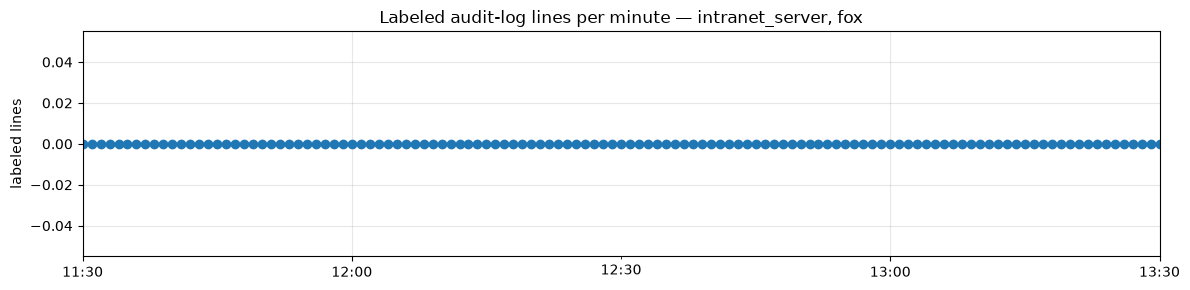

In [18]:
# For each log_type, bucket labeled line timestamps into 1-min bins
# and plot the result across the attack window.
#
# NOTE: this requires parsing a timestamp from each raw log line.
# Start with audit.log on the intranet_server — its format is
# msg=audit(<epoch>.<ms>:<id>) which is trivial to parse.
import re
from datetime import datetime

raw = GATHER / "intranet_server" / "logs" / "audit" / "audit.log"
lab = LABELS / "intranet_server" / "logs" / "audit" / "audit.log"

# labeled line numbers
labeled_lines = set()
for raw_json in open(lab):
    if raw_json.strip():
        labeled_lines.add(json.loads(raw_json)["line"])

ts_re = re.compile(r"msg=audit\((\d+)\.\d+:")
times, labels = [], []
for i, line in enumerate(open(raw), start=1):
    m = ts_re.search(line)
    if not m:
        continue
    times.append(datetime.fromtimestamp(int(m.group(1))))
    labels.append(1 if i in labeled_lines else 0)

s = pd.Series(labels, index=pd.DatetimeIndex(times))
s = s.groupby(pd.Grouper(freq="1min")).sum()

# Restrict to attack window (from Zenodo metadata: 11:59–13:15 on 2022-01-18)
win = s.loc["2022-01-18 11:30":"2022-01-18 13:30"]
win.plot(figsize=(12, 3), marker="o")
plt.title("Labeled audit-log lines per minute — intranet_server, fox")
plt.ylabel("labeled lines"); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [27]:
# Per-labeled-line timestamps in dnsmasq.log
import re
from datetime import datetime

dns = GATHER / "inet-firewall" / "logs" / "dnsmasq.log"
lab = LABELS / "inet-firewall" / "logs" / "dnsmasq.log"
labeled_lines = {json.loads(l)["line"] for l in open(lab) if l.strip()}

# dnsmasq format: "Jan 15 00:00:03 dnsmasq[...]"
ts_re = re.compile(r"^(\w{3}\s+\d+\s+\d{2}:\d{2}:\d{2})")
times = []
for i, line in enumerate(open(dns), start=1):
    if i in labeled_lines:
        m = ts_re.match(line)
        if m:
            times.append(datetime.strptime(f"2022 {m.group(1)}", "%Y %b %d %H:%M:%S"))

if times:
    span = (max(times) - min(times)).total_seconds()
    print(f"{len(times):,} labeled lines span {span:.0f}s ({span/60:.1f} min)")
    print(f"First: {min(times)}")
    print(f"Last:  {max(times)}")

44,600 labeled lines span 304706s (5078.4 min)
First: 2022-01-15 00:00:03
Last:  2022-01-18 12:38:29


---